# Name: Reol Audhasse, Submetric: Bus Stops

**Introduction:** 

Our group is trying to answer one question: *What is the best neighborhood in Pittsburgh?*
Each member of the team has their own submetric, and mine is **bus stops**. My idea:
I thinnk a neighborhood with a lot of bus service is a better place to live. You can get to school,
to work, and to the grocery store without needing a car. So good transit = freedom.

## My submetric: the Transit Score

Counting bus stops alone is not enough. A stop where only 2 buses pass per day is not worth
much, while a stop on a main corridor can serve 100+ buses a day. So I use the **number of
weekday trips** (`trips_wd`) of every stop, and my submetric is:

**Transit Score of a neighborhood = the total number of weekday bus trips at all its stops.**

This measures the real bus service a neighborhood receives, not just the number of poles
in the ground. Then I normalize the score from 0 to 1 so the group can combine it with
the other submetrics.

## The data

I use the **Pittsburgh Regional Transit Stops** dataset from the WPRDC:
https://data.wprdc.org/dataset/prt-of-allegheny-county-transit-stops

It contains every transit stop in Allegheny County (6358 stops) with the routes that serve
each stop and the number of trips per week. Even better: it already has a **neighborhood
column** (`hood`), so I don't need a spatial join this time — just filtering and grouping.

In [2]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# I read the file straight from the WPRDC link, so nobody in the group
# has to download anything by hand. It works the same on JupyterHub.
stops = gpd.read_file(
    "https://data.wprdc.org/dataset/33d5f44b-5315-4374-b3e3-e4246e8ad5c9/resource/d6e6ed6e-9220-4a0e-9796-e72d83ce8e7a/download/stops.geojson"
)

print(stops.shape)
stops.head(3)

ModuleNotFoundError: No module named 'geopandas'

## Step 1: Exploring the stops data

The dataset covers all of Allegheny County, not just the city of Pittsburgh.
I need to keep only the stops inside Pittsburgh neighborhoods.

In [2]:
# Each row is one transit stop. The useful columns for me:
# 'hood' = neighborhood, 'trips_wd' = weekday trips at that stop,
# 'mode' = BUS, RAIL (light rail) or INCLINE, 'muni' = municipality.
stops[["stop_name", "mode", "trips_wd", "muni", "hood"]].head()

,stop_name,mode,trips_wd,muni,hood
0,26TH ST AT PENN AVE FS (SPRING WAY),BUS,120,"Pittsburgh city (Allegheny, PA)",Strip District
1,28TH ST AT LIBERTY AVE,BUS,28,"Pittsburgh city (Allegheny, PA)",Polish Hill
2,32ND ST AT SPRING WAY,BUS,119,"Pittsburgh city (Allegheny, PA)",Strip District
3,40TH ST AT BUTLER ST,BUS,30,"Pittsburgh city (Allegheny, PA)",Lower Lawrenceville
4,40TH ST AT DAVIDSON ST FS,BUS,30,"Pittsburgh city (Allegheny, PA)",Central Lawrenceville


In [3]:
# 6358 stops total, almost all of them bus stops.
# There is also light rail (RAIL) and the Duquesne/Monongahela inclines (INCLINE).
print(stops["mode"].value_counts())

# How many stops are actually inside the City of Pittsburgh?
in_pgh = stops["muni"].str.contains("Pittsburgh", na=False)
print("Stops inside Pittsburgh:", in_pgh.sum())

mode
BUS        6254
RAIL        100
INCLINE       4
Name: count, dtype: int64
Stops inside Pittsburgh: 2693


## Step 2: Keeping only Pittsburgh stops

I filter to stops inside the City of Pittsburgh. The other stops are in the suburbs
(Monroeville, Wilkinsburg, etc.) and are not part of our neighborhood competition.

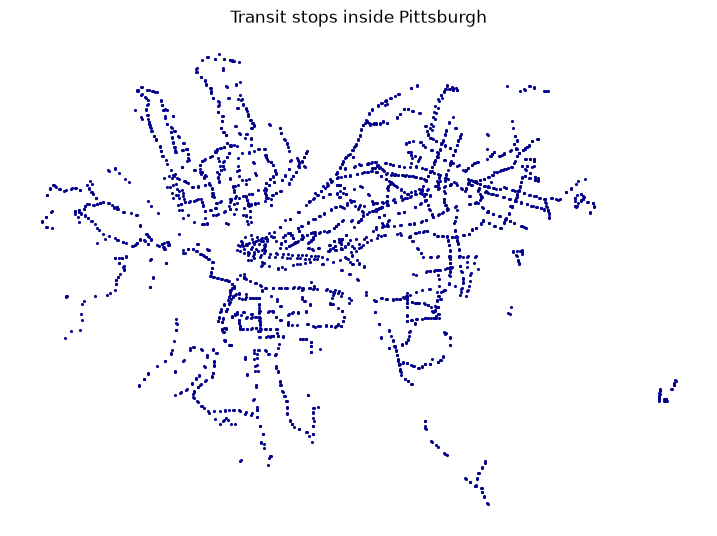

In [4]:
# Keep only the stops inside the City of Pittsburgh.
pgh_stops = stops[in_pgh].copy()

# Quick map of the stops so we can see they fill the city nicely.
pgh_stops.plot(markersize=1.5, color="darkblue", figsize=(9, 9))
plt.title("Transit stops inside Pittsburgh")
plt.axis("off");

In [5]:
# 89 of the 90 official neighborhoods have at least one stop. Only one is missing.
print("Neighborhoods with stops:", pgh_stops["hood"].nunique())

missing = set(neighborhoods_hoods := set()) # placeholder, filled below
all_hoods = gpd.read_file(
    "https://data.wprdc.org/dataset/e672f13d-71c4-4a66-8f38-710e75ed80a4/resource/4af8e160-57e9-4ebf-a501-76ca1b42fc99/download/neighborhoods.geojson"
)["hood"]
print("Missing:", set(all_hoods) - set(pgh_stops["hood"]))

Neighborhoods with stops: 89


Missing: {'Arlington Heights', 'Arlington'}


## Step 3: Computing the Transit Score

Now I group the stops by neighborhood and I add up the weekday trips. This is my submetric.

In [6]:
scores = (
    pgh_stops.groupby("hood")
    .agg(stop_count=("stop_id", "size"), trips_wd=("trips_wd", "sum"))
    .rename(columns={"trips_wd": "transit_score"})
    .sort_values("transit_score", ascending=False)
)
scores.head(10)

,stop_count,transit_score
hood,,
Central Business District,71,14647
North Oakland,42,8192
Squirrel Hill North,74,7771
Shadyside,76,7564
West Oakland,32,6411
East Liberty,63,6245
Bloomfield,89,6007
Squirrel Hill South,70,5729
South Side Flats,44,4450


In [7]:
# Note the difference with a simple stop count: Mount Washington has the most stops
# (97) but is only 11th by service, because many are little-served stops.
# Service, not stop count, is what actually matters.
print(scores.sort_values("stop_count", ascending=False).head(3))

                          stop_count  transit_score
hood                                               
Mount Washington                  97           3334
Bloomfield                        89           6007
Lincoln-Lemington-Belmar          80           4151


## Step 4: Visualizing the results

Here is my top 10 by Transit Score. Downtown dominates, which makes sense: almost every
bus route in the city passes through the Central Business District. The university
neighborhoods (North and West Oakland) and the East End corridors (Squirrel Hill,
Shadyside, East Liberty) follow.

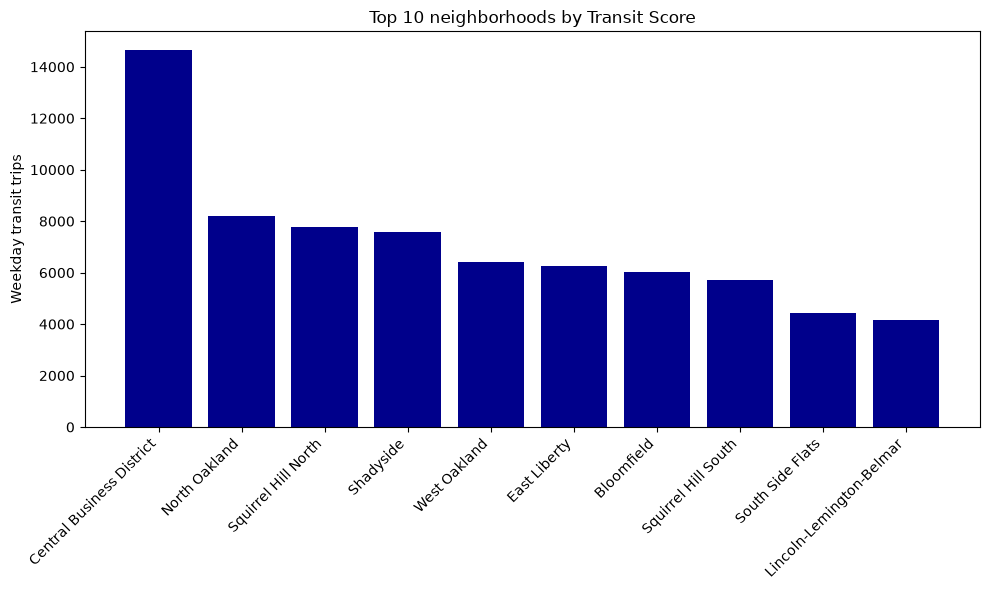

In [8]:
top10 = scores.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(top10.index, top10["transit_score"], color="darkblue")
ax.set_title("Top 10 neighborhoods by Transit Score")
ax.set_ylabel("Weekday transit trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout();

And a map of the whole city, where darker blue means a higher Transit Score.

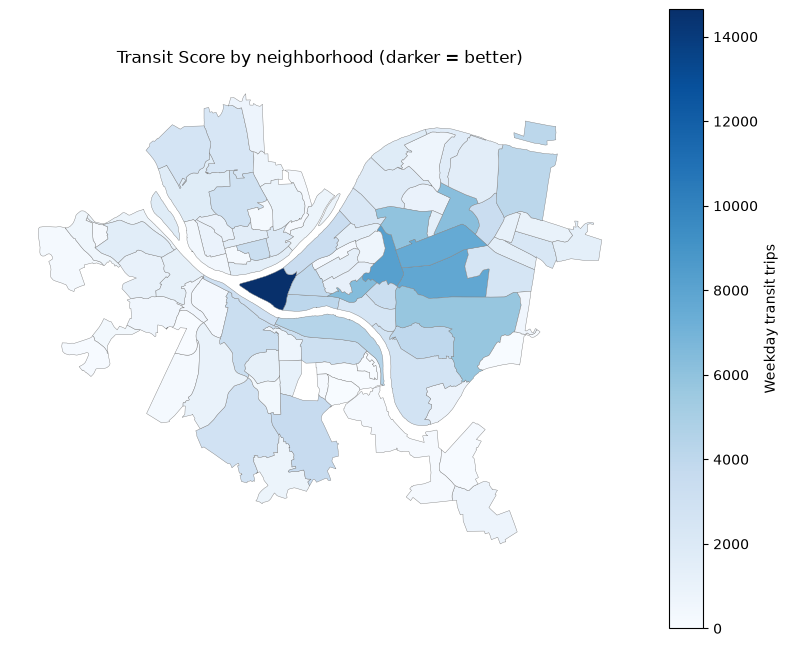

In [9]:
# Merge the scores into the neighborhood shapes so I can color the map.
hoods = gpd.read_file(
    "https://data.wprdc.org/dataset/e672f13d-71c4-4a66-8f38-710e75ed80a4/resource/4af8e160-57e9-4ebf-a501-76ca1b42fc99/download/neighborhoods.geojson"
)[["hood", "geometry"]]

map_data = hoods.merge(scores, left_on="hood", right_index=True, how="left")
map_data["transit_score"] = map_data["transit_score"].fillna(0)

fig, ax = plt.subplots(figsize=(10, 9))
map_data.plot(
    column="transit_score",
    cmap="Blues",
    edgecolor="gray",
    linewidth=0.3,
    legend=True,
    legend_kwds={"label": "Weekday transit trips"},
    ax=ax,
)
ax.set_title("Transit Score by neighborhood (darker = better)")
ax.axis("off");

## Step 5: Normalized score for the group metric

I rescale my Transit Score to go from 0 (no service) to 1 (the best neighborhood), so the
team can combine it with the other submetrics fairly.

In [10]:
scores["transit_score_norm"] = scores["transit_score"] / scores["transit_score"].max()
scores[["stop_count", "transit_score", "transit_score_norm"]].head(10)

,stop_count,transit_score,transit_score_norm
hood,,,
Central Business District,71,14647,1.000000
North Oakland,42,8192,0.559295
Squirrel Hill North,74,7771,0.530552
Shadyside,76,7564,0.516420
West Oakland,32,6411,0.437701
East Liberty,63,6245,0.426367
Bloomfield,89,6007,0.410118
Squirrel Hill South,70,5729,0.391138
South Side Flats,44,4450,0.303816


## My conclusion

**My submetric says the best neighborhood in Pittsburgh is the Central Business District.**
With 71 stops and 14,647 weekday trips, it has about twice the transit service of the second
place, North Oakland (8,192). After that come Squirrel Hill North, Shadyside, and West
Oakland.

What I find interesting is that the number of stops can be misleading: Mount Washington has
the most stops of any neighborhood (97), but many of them are served by only a few buses,
so it is only 11th by actual service. Counting weekday trips instead of stops gives a much
more honest picture of what it feels like to live there without a car.

One honest limitation: my metric loves Downtown because every bus line passes through it,
but a neighborhood like Oakland also has the campuses and jobs that people are actually
riding to. The metric measures transit supply, not how nice the neighborhood is overall —
that is exactly why we combine several submetrics as a group.

*The Central Business District is not my personal favorite neighborhood in Pittsburgh because I have other criteria for choosing the best neighborhood. My favorite neighborhood is Highland Park because it is calm, and the park is beautiful. It is a nice place for a date, an event, or just spending time alone, walking around, and exercising. In my experience, it does not feel too crowded or noisy. People usually go there with a specific purpose, such as attending a wedding or a graduation party. Even though the Central Business District ranks first according to my transit metric, I personally prefer the peaceful atmosphere of Highland Park.